<a href="https://colab.research.google.com/github/boboren2/Team-14/blob/main/Maincode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import pandas as pd

BASE = "/content/drive/MyDrive/Project Labs/"
FILES = ["pp-2023.csv", "pp-2024.csv", "pp-2025 (1).csv"]

COLS = ["id","price","date","postcode","prop_type","new_build","tenure",
        "paon","saon","street","locality","town","district","county",
        "ppd_cat","record_status"]
KEEP = ["id","price","date","postcode","prop_type","new_build","tenure",
        "district","ppd_cat","record_status"]
AREAS = ["EAST RIDING OF YORKSHIRE", "EAST LINDSEY"]

parts = []
for f in FILES:
    df = pd.read_csv(BASE + f, header=None, names=COLS, usecols=KEEP,
                     keep_default_na=False)
    print(f, "rows in whole country file:", len(df))
    parts.append(df[df["district"].isin(AREAS)])

sales = pd.concat(parts, ignore_index=True)
print("Rows in the two authorities:", len(sales))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pp-2023.csv rows in whole country file: 861782
pp-2024.csv rows in whole country file: 932214
pp-2025 (1).csv rows in whole country file: 992278
Rows in the two authorities: 29916


In [ ]:
(sales == "").sum()

,0
id,0
price,0
date,0
postcode,51
prop_type,0
new_build,0
tenure,0
district,0
ppd_cat,0
record_status,0


In [ ]:
print("Repeated ids:", sales["id"].duplicated().sum())
sales = sales.drop_duplicates("id")

Repeated ids: 0


In [ ]:
#irregular spellings
for col in ["district", "prop_type", "new_build", "tenure", "ppd_cat", "record_status"]:
    print(sales[col].value_counts(), "\n")

sales["postcode"] = sales["postcode"].str.strip().str.upper()
print("Postcodes in wrong format:",
      (~sales["postcode"].str.match(r"^[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}$")).sum())


district
EAST RIDING OF YORKSHIRE    21861
EAST LINDSEY                 8055
Name: count, dtype: int64 

prop_type
D    11259
S     9725
T     5747
O     1671
F     1514
Name: count, dtype: int64 

new_build
N    24915
Y     5001
Name: count, dtype: int64 

tenure
F    28031
L     1885
Name: count, dtype: int64 

ppd_cat
A    25139
B     4777
Name: count, dtype: int64 

record_status
A    29916
Name: count, dtype: int64 

Postcodes in wrong format: 51


In [ ]:
sales["date"] = pd.to_datetime(sales["date"], format="%Y-%m-%d %H:%M")
sales["price"] = pd.to_numeric(sales["price"])
print(sales[["price", "date"]].describe())

              price                           date
count  2.991600e+04                          29916
mean   2.578691e+05  2024-07-27 04:24:30.036101120
min    1.000000e+02            2023-01-03 00:00:00
25%    1.567490e+05            2023-10-26 00:00:00
50%    2.150000e+05            2024-08-14 00:00:00
75%    3.000000e+05            2025-04-17 00:00:00
max    2.910000e+07            2025-12-23 00:00:00
std    3.424781e+05                            NaN


In [ ]:
print("Not standard sale (ppd_cat B):", (sales["ppd_cat"] != "A").sum())
print("Property type Other:", (sales["prop_type"] == "O").sum())
print("No postcode:", (sales["postcode"] == "").sum())
print("Tenure not F or L:", (~sales["tenure"].isin(["F", "L"])).sum())
print("Price of 0 or less:", (sales["price"] <= 0).sum())
print("Dates outside 2023-2025:", (~sales["date"].dt.year.between(2023, 2025)).sum())

sales = sales[
    (sales["ppd_cat"] == "A")
    & (sales["prop_type"] != "O")
    & (sales["postcode"] != "")
    & (sales["tenure"].isin(["F", "L"]))
    & (sales["price"] > 0)
].copy()

Not standard sale (ppd_cat B): 4777
Property type Other: 1671
No postcode: 51
Tenure not F or L: 0
Price of 0 or less: 0
Dates outside 2023-2025: 0


In [ ]:
sales["year"] = sales["date"].dt.year
sales["pc_district"] = sales["postcode"].str.split(" ").str[0]
sales = sales[["id","price","date","year","postcode","pc_district",
               "prop_type","new_build","tenure","district"]]

print(sales.shape)
print(sales.groupby(["district", "year"]).size().unstack())
sales.to_csv(BASE + "sales_clean.csv", index=False)
print("Saved", len(sales), "rows")

(25129, 10)
year                      2023  2024  2025
district                                  
EAST LINDSEY              2061  2167  2403
EAST RIDING OF YORKSHIRE  5746  6066  6686
Saved 25129 rows


In [3]:
#flood
flood = pd.read_csv(BASE + "floodriskbands.csv",
                    encoding="utf-8-sig", keep_default_na=False, dtype=str,
                    usecols=["PC","RES_cntpc","RES_CNT_VeryLow","RES_CNT_Low",
                             "RES_CNT_Medium","RES_CNT_High"])
flood.columns = ["postcode","res_total","res_vlow","res_low","res_medium","res_high"]
print(flood.shape)
flood.head()

Mounted at /content/drive
(271449, 6)


,postcode,res_total,res_vlow,res_low,res_medium,res_high
0,NR29 5AB,15,7,0,0,0
1,KT2 5BG,60,0,0,60,0
2,NR14 7ED,5,0,0,0,0
3,OL12 8HF,13,0,0,0,6
4,CB9 7UT,45,15,0,0,0


In [7]:
print("Blank cells per column:\n", (flood == "").sum(), "\n")

print("Wildcard postcodes (end in *):", flood["postcode"].str.endswith("*").sum())
flood = flood[~flood["postcode"].str.endswith("*")].copy()
print("Rows left:", len(flood))

flood["postcode"] = flood["postcode"].str.strip().str.upper()
print("Repeated postcodes:", flood["postcode"].duplicated().sum())

ok_format = flood["postcode"].str.match(r"^[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}$")
print("Wrong format (not real postcodes):", (~ok_format).sum())
flood = flood[ok_format].copy()


Blank cells per column:
 postcode      0
res_total     0
res_vlow      0
res_low       0
res_medium    0
res_high      0
dtype: int64 

Wildcard postcodes (end in *): 0
Rows left: 165227
Repeated postcodes: 0
Wrong format (not real postcodes): 60


In [8]:
for c in ["res_total","res_vlow","res_low","res_medium","res_high"]:
    flood[c] = pd.to_numeric(flood[c])

flood["res_banded"] = flood[["res_vlow","res_low","res_medium","res_high"]].sum(axis=1)
print("No residential homes:", (flood["res_total"] == 0).sum())
print("Banded homes exceed total homes:", (flood["res_banded"] > flood["res_total"]).sum())
print("Negative counts:", (flood[["res_total","res_vlow","res_low","res_medium","res_high"]] < 0).sum().sum())
print("Postcodes with at least one banded home:", (flood["res_banded"] > 0).sum())

No residential homes: 19103
Banded homes exceed total homes: 0
Negative counts: 0
Postcodes with at least one banded home: 129670


In [9]:
flood = flood[flood["res_total"] > 0].copy()
for b in ["vlow","low","medium","high"]:
    flood["share_" + b] = flood["res_" + b] / flood["res_total"]
flood["share_none"] = 1 - flood[["share_vlow","share_low","share_medium","share_high"]].sum(axis=1)

flood = flood[["postcode","res_total","res_vlow","res_low","res_medium","res_high",
               "share_vlow","share_low","share_medium","share_high","share_none"]]
print(flood.shape)
flood.to_csv(BASE + "flood_postcode.csv", index=False)

(146064, 11)


In [10]:
sales = pd.read_csv(BASE + "sales_clean.csv", parse_dates=["date"], keep_default_na=False)
flood = pd.read_csv(BASE + "flood_postcode.csv", keep_default_na=False)
print(sales.shape, flood.shape)

(25129, 10) (146064, 11)


In [11]:
merged = sales.merge(flood, on="postcode", how="inner", validate="many_to_one")
print("Sales kept:", len(merged), "of", len(sales), "(", round(len(merged)/len(sales)*100, 1), "% )")
print(merged.groupby(["district","year"]).size().unstack())

Sales kept: 7964 of 25129 ( 31.7 % )
year                      2023  2024  2025
district                                  
EAST LINDSEY               916   984  1055
EAST RIDING OF YORKSHIRE  1566  1652  1791


In [12]:
print((merged.groupby("district").size() / sales.groupby("district").size()).round(3))
print(merged["pc_district"].value_counts().head(10))

band_cols = ["share_vlow","share_low","share_medium","share_high"]
merged["has_banded_homes"] = merged[band_cols].sum(axis=1) > 0
merged["dominant_band"] = (merged[band_cols].idxmax(axis=1).str.replace("share_","")
                           .where(merged["has_banded_homes"], "none"))
print(merged["dominant_band"].value_counts())

print("Sales in the flood file but with no banded homes:", (~merged["has_banded_homes"]).sum())
main = merged[merged["has_banded_homes"]].copy()
print("Main sample:", len(main))
main.to_csv(BASE + "sales_flood_inner.csv", index=False)

district
EAST LINDSEY                0.446
EAST RIDING OF YORKSHIRE    0.271
dtype: float64
pc_district
DN14    1582
PE25     857
HU12     652
LN12     642
PE24     437
HU15     418
HU17     374
HU13     335
LN11     305
HU16     286
Name: count, dtype: int64
dominant_band
vlow      3167
low       1874
high      1470
medium    1164
none       289
Name: count, dtype: int64
Sales in the flood file but with no banded homes: 289
Main sample: 7675


In [13]:
#Inclusion of postcodes with no riskbands for checks
merged_all = sales.merge(flood, on="postcode", how="left", validate="many_to_one")
merged_all["in_flood_file"] = merged_all["res_total"].notna()
for c in ["share_vlow","share_low","share_medium","share_high"]:
    merged_all[c] = merged_all[c].fillna(0)
merged_all["share_none"] = merged_all["share_none"].fillna(1)
print(merged_all["in_flood_file"].value_counts())
merged_all.to_csv(BASE + "sales_flood_left.csv", index=False)

in_flood_file
False    17165
True      7964
Name: count, dtype: int64


In [16]:
import matplotlib.pyplot as plt
data = pd.read_csv(BASE + "sales_flood_inner.csv", parse_dates=["date"])
order = ["vlow", "low", "medium", "high"]

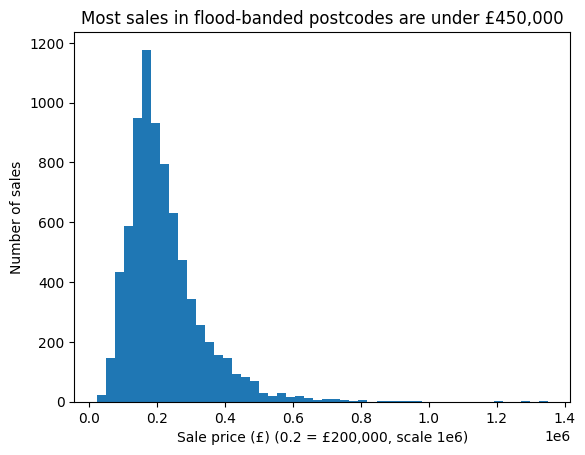

Median: 195000.0
Middle half: 150000.0 to 267500.0


In [18]:
data["price"].plot(kind="hist", bins=50, title="Most sales in flood-banded postcodes are under £450,000")
plt.xlabel("Sale price (£) 0.2 = £200,000, scale 1e6)")
plt.ylabel("Number of sales")
plt.show()
print("Median:", data["price"].median())
print("Middle half:", data["price"].quantile(0.25), "to", data["price"].quantile(0.75))

In [76]:
types = {"D": "Detached", "S": "Semi-detached", "T": "Terraced", "F": "Flat"}
bands = ["vlow", "low", "medium", "high"]

# sales in each property type, district and band (0 if none)
counts = (data.groupby(["prop_type", "pc_district", "dominant_band"]).size()
          .unstack(fill_value=0).reindex(columns=order, fill_value=0))

rows = []
for code, tname in types.items():
    c = counts.loc[code]
    for b in bands:
        both = c[(c["none"] >= 1) & (c[b] >= 1)]            # complete cases: district has both groups
        rows.append({
            "property type": tname,
            "band": b,
            "banded sales (all)": int(c[b].sum()),
            "no-risk sales (all)": int(c["none"].sum()),
            "districts with both groups": len(both),
            "banded sales in those": int(both[b].sum()),
            "no-risk sales in those": int(both["none"].sum()),
        })
summary = pd.DataFrame(rows).set_index(["property type", "band"])
summary["share of banded sales kept"] = (summary["banded sales in those"] / summary["banded sales (all)"]).round(2)
display(summary)

banded sales (all)  no-risk sales (all)  \
property type band                                              
Detached      vlow                  1384                 7564   
              low                    649                 7564   
              medium                 300                 7564   
              high                   690                 7564   
Semi-detached vlow                  1179                 5946   
              low                    616                 5946   
              medium                 379                 5946   
              high                   490                 5946   
Terraced      vlow                   454                 3073   
              low                    494                 3073   
              medium                 428                 3073   
              high                   231                 3073   
Flat          vlow                   150                  871   
              low                    115                  871   
              medium                  57                  871   
              high                    59                  871   

                      districts with both groups  banded sales in those  \
property type band                                                        
Detached      vlow                            23                   1190   
              low                             29                    588   
              medium                          19                    287   
              high                            21                    585   
Semi-detached vlow                            25                   1151   
              low                             29                    616   
              medium                          19                    379   
              high                            21                    472   
Terraced      vlow                            22                    368   
              low                             24                    389   
              medium                          13                    424   
              high                            12                    215   
Flat          vlow                            10                     89   
              low                             10                     42   
              medium                           9                     41   
              high                             7                     45   

                      no-risk sales in those  share of banded sales kept  
property type band                                                        
Detached      vlow                      5819                        0.86  
              low                       7539                        0.91  
              medium                    4956                        0.96  
              high                      6122                        0.85  
Semi-detached vlow                      4400                        0.98  
              low                       5780                        1.00  
              medium                    4537                        1.00  
              high                      4719                        0.96  
Terraced      vlow                      2442                        0.81  
              low                       2903                        0.79  
              medium                    1686                        0.99  
              high                      1851                        0.93  
Flat          vlow                       273                        0.59  
              low                        597                        0.37  
              medium                     465                        0.72  
              high                       200                        0.76

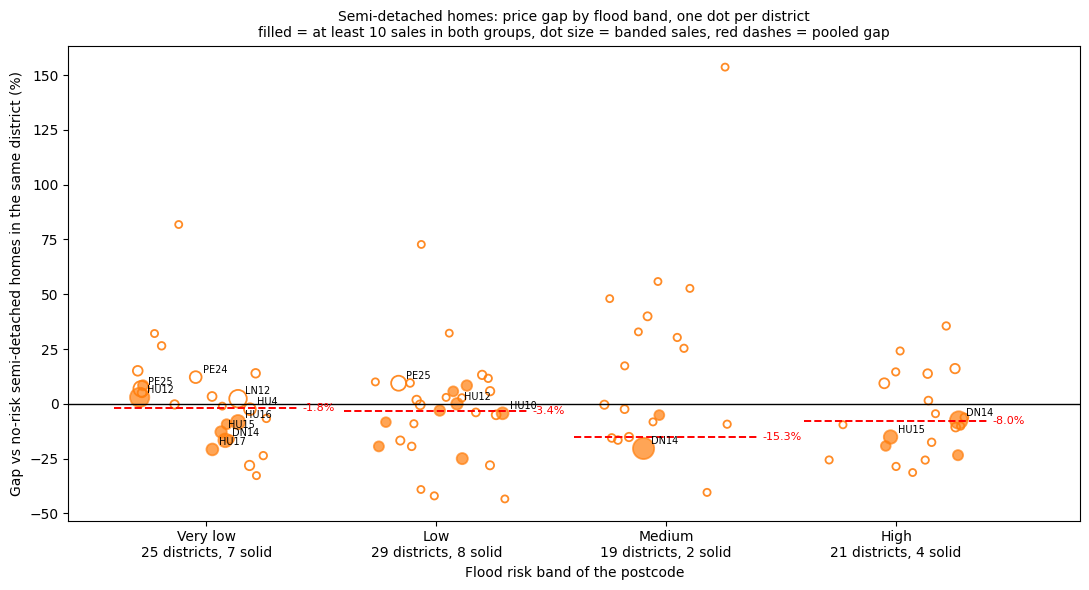

In [65]:
PROP_TYPE = "S"
THIN = 30
bands = ["vlow", "low", "medium", "high"]
names = {"vlow": "Very low", "low": "Low", "medium": "Medium", "high": "High"}

# median price and number of sales for each district and band (including none)
g = use.groupby(["pc_district", "dominant_band"])["price"].agg(median="median", n="size").unstack()
rows = []
for b in bands:
    t = pd.DataFrame({
        "pc_district": g.index,
        "gap": (g[("median", b)] / g[("median", "none")] - 1) * 100,
        "n_band": g[("n", b)],
        "n_none": g[("n", "none")],
    }).dropna()
    t["band"] = b
    rows.append(t)
dist = pd.concat(rows, ignore_index=True)
dist["thin"] = (dist["n_band"] < THIN) | (dist["n_none"] < THIN)

# pooled gap
bench = use[use["dominant_band"] == "none"].groupby("pc_district")["price"].median().rename("none_median")
sales_gap = use[use["dominant_band"] != "none"].join(bench, on="pc_district").dropna(subset=["none_median"])
sales_gap["gap"] = (sales_gap["price"] / sales_gap["none_median"] - 1) * 100
pooled = sales_gap.groupby("dominant_band")["gap"].median()

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(0)
for k, b in enumerate(bands):
    d = dist[dist["band"] == b]
    x = k + rng.uniform(-0.3, 0.3, len(d))
    for thin, hollow in [(False, False), (True, True)]:
        m = d["thin"].values == thin
        ax.scatter(x[m], d["gap"].values[m], s=d["n_band"].values[m] * 0.8 + 25,
                   facecolor="none" if hollow else "#ff7f0e", edgecolor="#ff7f0e", linewidth=1.3,
                   alpha=0.9 if hollow else 0.7)
    for xi, (_, r) in zip(x, d.iterrows()):
        if r["n_band"] >= 50:
            ax.annotate(r["pc_district"], (xi, r["gap"]), xytext=(5, 3), textcoords="offset points", fontsize=7)
    ax.hlines(pooled[b], k - 0.4, k + 0.4, color="red", linestyle="--", linewidth=1.4)
    ax.text(k + 0.42, pooled[b], f"{pooled[b]:+.1f}%", color="red", fontsize=8, va="center")
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{names[b]}\n{(dist['band']==b).sum()} districts, {int((~dist[dist['band']==b]['thin']).sum())} solid"
                    for b in bands])
ax.set_xlim(-0.6, 3.8)
ax.set_xlabel("Flood risk band of the postcode")
ax.set_ylabel("Gap vs no-risk semi-detached homes in the same district (%)")
ax.set_title(f"Semi-detached homes: price gap by flood band, one dot per district\n"
             "filled = at least 10 sales in both groups, dot size = banded sales, red dashes = pooled gap",
             fontsize=10)
plt.tight_layout()
plt.show()

In [66]:
print(g.head())

                 median                                              n        \
dominant_band      high       low    medium      none      vlow   high   low   
pc_district                                                                    
DN14           200000.0  215000.0  172000.0  216000.0  180000.0  169.0  21.0   
DN36           132500.0  105000.0       NaN  185500.0  185000.0    4.0   1.0   
HU10           210000.0  248750.0  217000.0  260000.0  282000.0   30.0  60.0   
HU11           127000.0  190000.0       NaN  185000.0       NaN    1.0   5.0   
HU12           159500.0  170000.0  161250.0  170000.0  175000.0    8.0  55.0   

                                    
dominant_band medium   none   vlow  
pc_district                         
DN14           260.0  120.0   90.0  
DN36             NaN   84.0   15.0  
HU10             7.0  351.0   35.0  
HU11             NaN  169.0    NaN  
HU12            32.0  210.0  209.0  


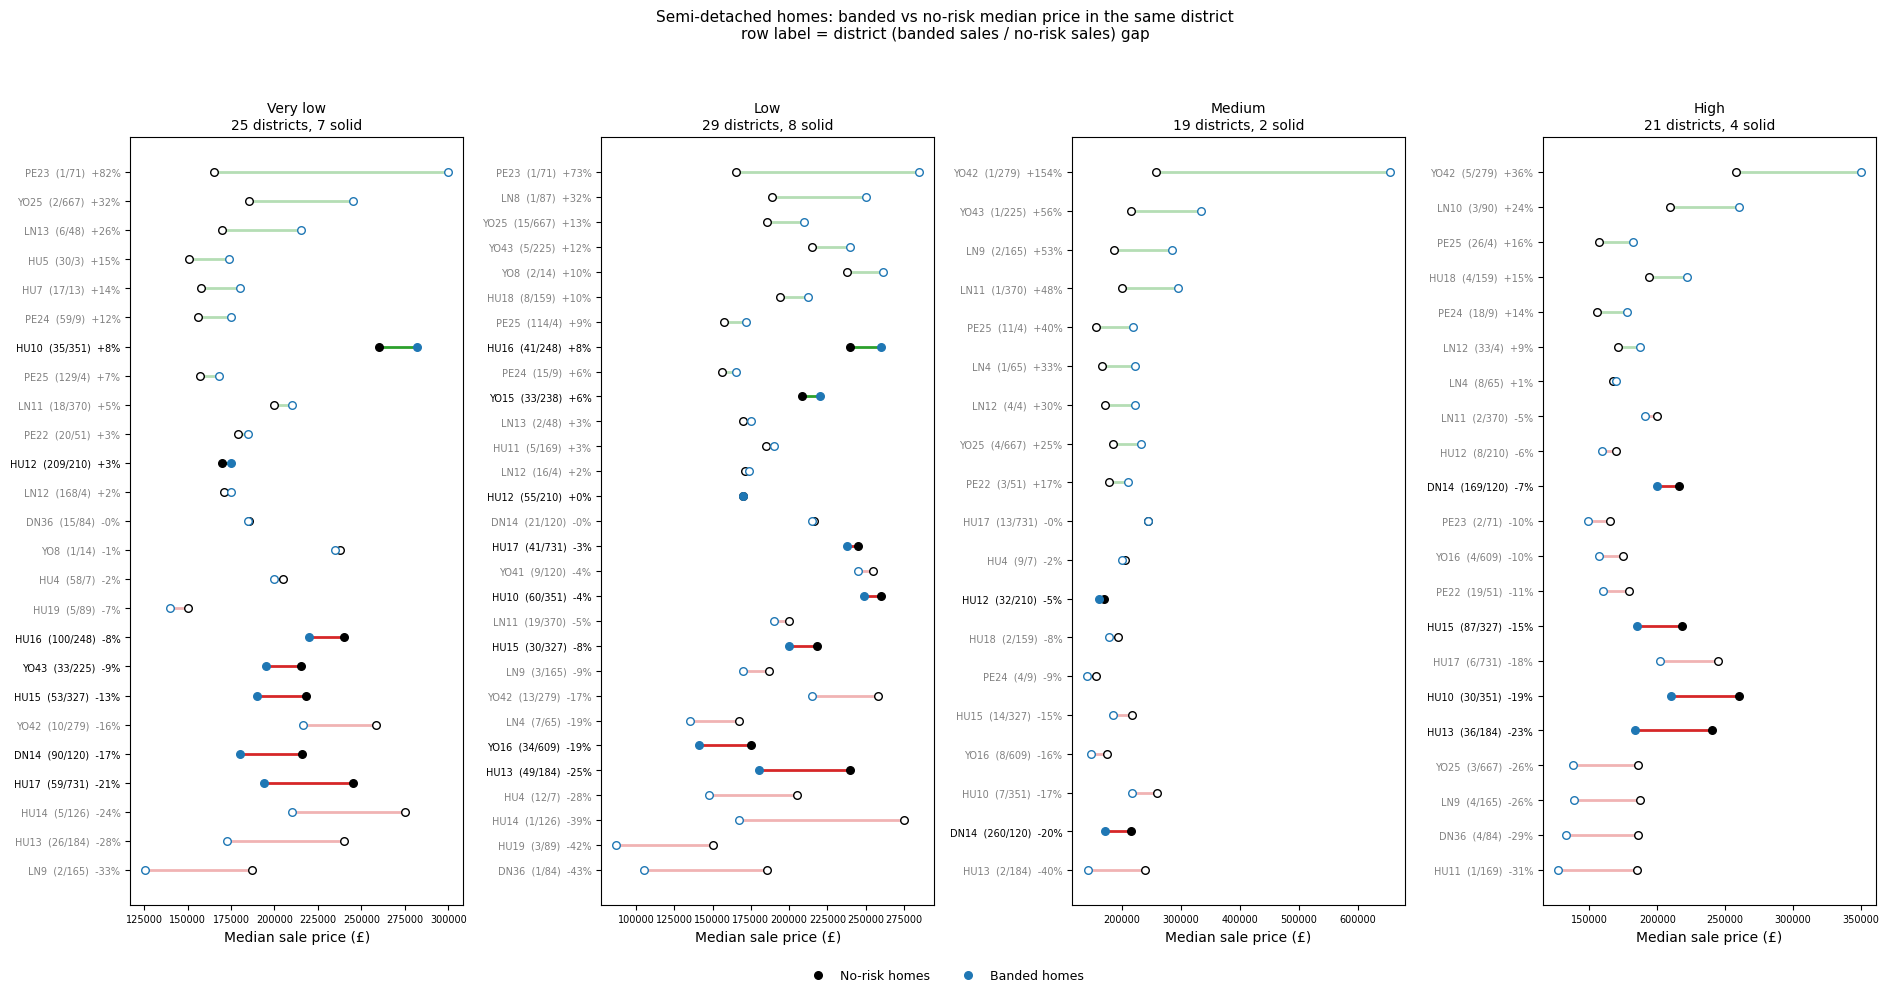

In [79]:
PROP_TYPE = "S"
THIN = 30
bands = ["vlow", "low", "medium", "high"]
names = {"vlow": "Very low", "low": "Low", "medium": "Medium", "high": "High"}

use = data[data["prop_type"] == PROP_TYPE]

# median price and number of sales for each district and band (including none)
g = use.groupby(["pc_district", "dominant_band"])["price"].agg(median="median", n="size").unstack()

fig, axes = plt.subplots(1, 4, figsize=(19, 10))
for ax, b in zip(axes, bands):
    t = pd.DataFrame({
        "none": g[("median", "none")], "banded": g[("median", b)],
        "n_none": g[("n", "none")], "n_band": g[("n", b)],
    }).dropna()
    t["gap"] = (t["banded"] / t["none"] - 1) * 100
    t["thin"] = (t["n_none"] < THIN) | (t["n_band"] < THIN)
    t = t.sort_values("gap", ascending=False)
    y = np.arange(len(t))
    for i, (_, r) in enumerate(t.iterrows()):
        col = "#d62728" if r["gap"] < 0 else "#2ca02c"
        ax.plot([r["none"], r["banded"]], [i, i], color=col, linewidth=2, alpha=0.35 if r["thin"] else 1, zorder=1)
    solid, thin = t[~t["thin"]], t[t["thin"]]
    ys, yt = y[(~t["thin"]).values], y[t["thin"].values]
    ax.scatter(solid["none"], ys, color="black", s=30, zorder=2, label="No-risk homes")
    ax.scatter(solid["banded"], ys, color="#1f77b4", s=30, zorder=2, label="Banded homes")
    ax.scatter(thin["none"], yt, facecolor="white", edgecolor="black", s=30, zorder=2)
    ax.scatter(thin["banded"], yt, facecolor="white", edgecolor="#1f77b4", s=30, zorder=2)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{d}  ({int(r.n_band)}/{int(r.n_none)})  {r.gap:+.0f}%" for d, r in t.iterrows()], fontsize=7)
    for lab, th in zip(ax.get_yticklabels(), t["thin"]):
        lab.set_color("grey" if th else "black")
    ax.invert_yaxis()
    ax.set_title(f"{names[b]}\n{len(t)} districts, {int((~t['thin']).sum())} solid", fontsize=10)
    ax.set_xlabel("Median sale price (£)")
    ax.ticklabel_format(style="plain", axis="x")
    ax.tick_params(axis="x", labelsize=7)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle(f"Semi-detached homes: banded vs no-risk median price in the same district\n"
             "row label = district (banded sales / no-risk sales) gap", fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()